Shape: (1000, 7)


,Attendance_Pct,Study_Hours,Assignment_Score,Previous_Exam_Score,Sleep_Hours,Internet_Access,Pass
0,82.0,5.2,57.2,31.6,5.9,Yes,1
1,73.1,4.5,65.7,49.4,6.8,Yes,1
2,84.1,3.3,55.3,57.0,6.8,Yes,1
3,96.3,2.3,63.1,96.1,7.3,Yes,1
4,71.7,4.2,37.7,73.5,5.3,Yes,1



Missing values:
 Attendance_Pct         0
Study_Hours            0
Assignment_Score       0
Previous_Exam_Score    0
Sleep_Hours            0
Internet_Access        0
Pass                   0
dtype: int64
Duplicate rows: 0

Class counts (0 = Fail, 1 = Pass):
 Pass
1    597
0    403
Name: count, dtype: int64


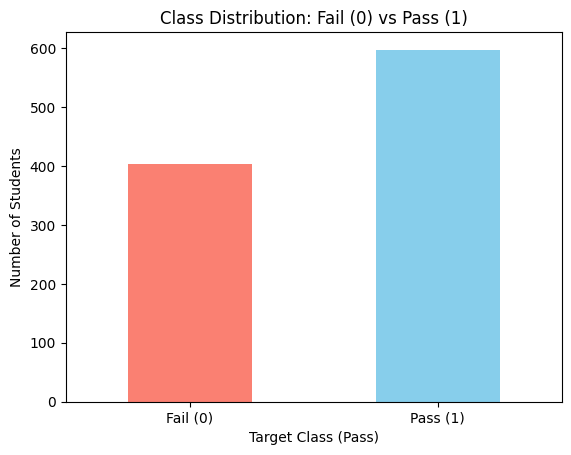

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, classification_report, roc_curve, roc_auc_score
)


df = pd.read_csv('student_performance.csv')

print("Shape:", df.shape)
display(df.head())
print("\nMissing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nClass counts (0 = Fail, 1 = Pass):\n", df['Pass'].value_counts())


df['Pass'].value_counts().sort_index().plot(kind='bar', color=['salmon', 'skyblue'])
plt.title('Class Distribution: Fail (0) vs Pass (1)')
plt.xlabel('Target Class (Pass)')
plt.ylabel('Number of Students')
plt.xticks([0, 1], ['Fail (0)', 'Pass (1)'], rotation=0)
plt.show()


In [3]:

X = df.drop('Pass', axis=1).copy()
y = df['Pass']


X['Internet_Access'] = X['Internet_Access'].map({'No': 0, 'Yes': 1})


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train.shape[0]} rows | Class counts: {y_train.value_counts().to_dict()}")
print(f"Testing set:  {X_test.shape[0]} rows | Class counts: {y_test.value_counts().to_dict()}")


Training set: 800 rows | Class counts: {1: 478, 0: 322}
Testing set:  200 rows | Class counts: {1: 119, 0: 81}


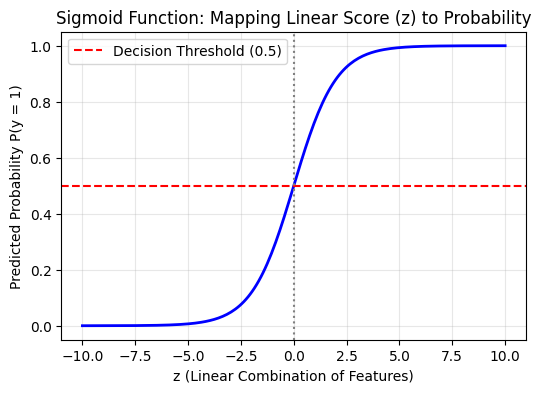

In [4]:

z = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(6, 4))
plt.plot(z, sigmoid, color='blue', linewidth=2)
plt.axhline(0.5, color='red', linestyle='--', label='Decision Threshold (0.5)')
plt.axvline(0, color='gray', linestyle=':')
plt.title('Sigmoid Function: Mapping Linear Score (z) to Probability')
plt.xlabel('z (Linear Combination of Features)')
plt.ylabel('Predicted Probability P(y = 1)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [5]:

model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0].round(4)
}).sort_values(by='Coefficient', ascending=False)

print(f"Intercept: {model.intercept_[0]:.4f}\n")
display(coef_df)


Intercept: 0.6802



,Feature,Coefficient
1,Study_Hours,1.1343
3,Previous_Exam_Score,1.0934
0,Attendance_Pct,0.9265
2,Assignment_Score,0.8011
5,Internet_Access,0.3992
4,Sleep_Hours,0.1783


In [6]:

y_prob = model.predict_proba(X_test_scaled)[:, 1]
y_pred = model.predict(X_test_scaled)

sample_results = pd.DataFrame({
    'Actual_Label': y_test.values[:10],
    'Predicted_Probability': np.round(y_prob[:10], 4),
    'Predicted_Label': y_pred[:10]
})
display(sample_results)


,Actual_Label,Predicted_Probability,Predicted_Label
0,1,0.9578,1
1,1,0.6995,1
2,0,0.2225,0
3,1,0.6349,1
4,0,0.5503,1
5,0,0.8783,1
6,1,0.7190,1
7,0,0.8976,1
8,1,0.9843,1
9,1,0.2097,0


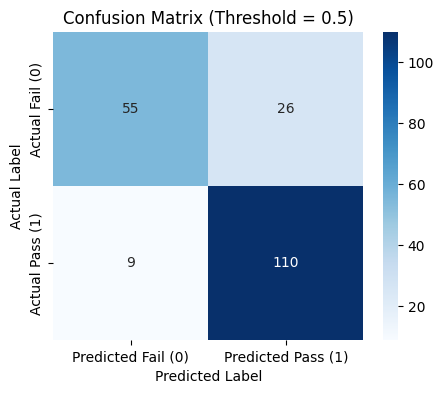

True Positives (TP):  110  (Correctly predicted Pass)
True Negatives (TN):  55  (Correctly predicted Fail)
False Positives (FP): 26  (Predicted Pass, actually Failed)
False Negatives (FN): 9  (Predicted Fail, actually Passed)


In [7]:

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Fail (0)', 'Predicted Pass (1)'],
            yticklabels=['Actual Fail (0)', 'Actual Pass (1)'])
plt.title('Confusion Matrix (Threshold = 0.5)')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

print(f"True Positives (TP):  {tp}  (Correctly predicted Pass)")
print(f"True Negatives (TN):  {tn}  (Correctly predicted Fail)")
print(f"False Positives (FP): {fp}  (Predicted Pass, actually Failed)")
print(f"False Negatives (FN): {fn}  (Predicted Fail, actually Passed)")


In [8]:

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

baseline_acc = max(y_test.mean(), 1 - y_test.mean())

metrics_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'Specificity', 'F1-Score', 'ROC-AUC'],
    'Test_Result': [accuracy, precision, recall, specificity, f1, roc_auc]
})
metrics_table['Test_Result'] = metrics_table['Test_Result'].round(4)
display(metrics_table)

print(f"Majority-Class Baseline Accuracy: {baseline_acc:.4f}")
print(f"Training Set Accuracy:            {model.score(X_train_scaled, y_train):.4f}")
print(f"Testing Set Accuracy:             {accuracy:.4f}\n")
print("Full Classification Report:\n", classification_report(y_test, y_pred, target_names=['Fail (0)', 'Pass (1)']))


,Metric,Test_Result
0,Accuracy,0.8250
1,Precision,0.8088
2,Recall (Sensitivity),0.9244
3,Specificity,0.6790
4,F1-Score,0.8627
5,ROC-AUC,0.8954


Majority-Class Baseline Accuracy: 0.5950
Training Set Accuracy:            0.7775
Testing Set Accuracy:             0.8250

Full Classification Report:
               precision    recall  f1-score   support

    Fail (0)       0.86      0.68      0.76        81
    Pass (1)       0.81      0.92      0.86       119

    accuracy                           0.82       200
   macro avg       0.83      0.80      0.81       200
weighted avg       0.83      0.82      0.82       200



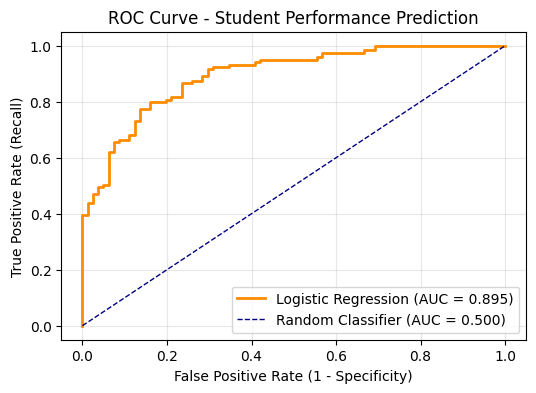

In [9]:

fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Logistic Regression (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Random Classifier (AUC = 0.500)')
plt.title('ROC Curve - Student Performance Prediction')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()


In [10]:

rows = []
for t in [0.3, 0.5, 0.7]:
    preds_t = (y_prob >= t).astype(int)
    rows.append({
        'Threshold': t,
        'Predicted_Positive': int(preds_t.sum()),
        'Accuracy': round(accuracy_score(y_test, preds_t), 4),
        'Precision': round(precision_score(y_test, preds_t), 4),
        'Recall': round(recall_score(y_test, preds_t), 4),
        'F1_Score': round(f1_score(y_test, preds_t), 4)
    })

threshold_df = pd.DataFrame(rows)
display(threshold_df)


,Threshold,Predicted_Positive,Accuracy,Precision,Recall,F1_Score
0,0.3,161,0.750,0.7143,0.9664,0.8214
1,0.5,136,0.825,0.8088,0.9244,0.8627
2,0.7,100,0.795,0.8900,0.7479,0.8128


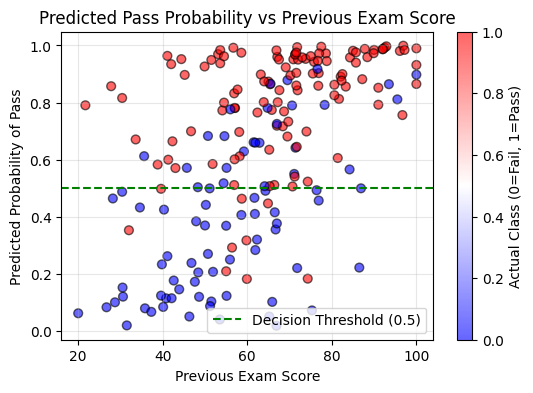

In [11]:

plt.figure(figsize=(6, 4))
plt.scatter(X_test['Previous_Exam_Score'], y_prob, c=y_test, cmap='bwr', alpha=0.6, edgecolors='k', s=40)
plt.axhline(0.5, color='green', linestyle='--', label='Decision Threshold (0.5)')
plt.title('Predicted Pass Probability vs Previous Exam Score')
plt.xlabel('Previous Exam Score')
plt.ylabel('Predicted Probability of Pass')
plt.colorbar(label='Actual Class (0=Fail, 1=Pass)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [12]:

new_student = pd.DataFrame([{
    'Attendance_Pct': 82.0,
    'Study_Hours': 4.0,
    'Assignment_Score': 75.0,
    'Previous_Exam_Score': 70.0,
    'Sleep_Hours': 7.0,
    'Internet_Access': 1
}])

new_student_scaled = scaler.transform(new_student)
new_prob = model.predict_proba(new_student_scaled)[0, 1]
new_pred = model.predict(new_student_scaled)[0]

print(f"Predicted Probability of Passing: {new_prob:.4f}")
print(f"Predicted Class: {'Pass (1)' if new_pred == 1 else 'Fail (0)'}")
print("\nNote: This prediction is a probability-based estimate, not a guaranteed outcome.")


Predicted Probability of Passing: 0.9450
Predicted Class: Pass (1)

Note: This prediction is a probability-based estimate, not a guaranteed outcome.
